# Heatwave Early Warning using Kernel-Based Classification
**Technique:** Support Vector Machine with RBF kernel · **Use case:** KJS-CES-01 (IMD Mumbai–Pune)

Goal: on the evening of day *t*, predict whether day *t+1* will be a heatwave day under the IMD criteria, for 10 Indian cities.

Dataset: [India Daily Weather (2000–2024) – Major Cities, Kaggle](https://www.kaggle.com/datasets/developerghost/climate-in-india-daily-weather-data-2000-2024)

In [1]:
import sys, json, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from features import load_raw, climatology, build_features, split, FEATURES, FEATURE_LABELS, CITIES
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
raw = load_raw('../data/india_2000_2024_daily_weather.csv')
print(raw.shape); raw.head()

(91320, 12)


,city,date,tmax,tmin,app_tmax,app_tmin,precip,rain,weather_code,wind_max,gust_max,wdir
0,Ahmedabad,2000-01-01,29.9,15.3,29.1,12.8,0.0,0.0,0,14.5,30.2,60
1,Ahmedabad,2000-01-02,29.9,16.1,28.8,13.2,0.0,0.0,0,15.3,29.5,68
2,Ahmedabad,2000-01-03,29.1,15.1,27.9,12.1,0.0,0.0,0,14.4,27.7,52
3,Ahmedabad,2000-01-04,28.6,13.7,27.5,11.2,0.0,0.0,0,12.4,21.6,45
4,Ahmedabad,2000-01-05,28.1,13.2,26.8,10.8,0.0,0.0,0,11.3,22.7,34


## 1. Exploratory analysis

In [2]:
print(raw.isna().sum().sum(), 'missing values')
raw.groupby('city')[['tmax','tmin','rain','wind_max']].describe().round(1).iloc[:, [1,2,7,9,10,15]]

0 missing values


tmax             tmin           
           mean  std   max  mean  std   max
city                                       
Ahmedabad  33.2  4.5  46.4  21.8  4.9  32.3
Bangalore  28.3  3.0  39.4  18.6  2.4  25.0
Chennai    31.9  3.3  41.9  24.9  2.6  31.5
Delhi      30.6  6.8  46.4  19.3  7.3  34.4
Hyderabad  31.2  3.9  42.2  21.4  3.5  31.1
Jaipur     31.1  6.3  46.4  19.4  7.0  32.8
Kolkata    30.7  3.8  43.9  22.2  5.1  30.6
Lucknow    30.8  6.1  46.3  20.0  6.8  33.7
Mumbai     30.5  2.4  41.4  23.6  2.9  29.6
Pune       30.7  4.1  42.9  20.2  3.0  27.8

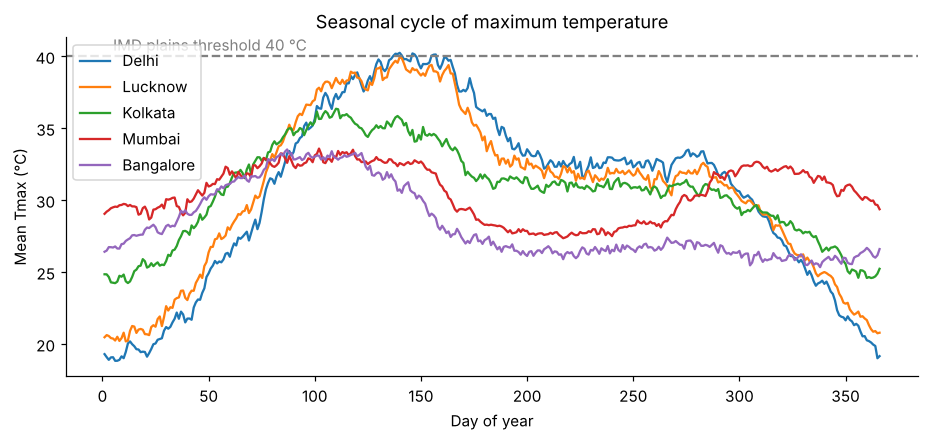

In [3]:
fig, ax = plt.subplots(figsize=(10,4))
for c in ['Delhi','Lucknow','Kolkata','Mumbai','Bangalore']:
    s = raw[raw.city==c].groupby(raw.date.dt.dayofyear).tmax.mean()
    ax.plot(s.index, s.values, label=c)
ax.axhline(40, ls='--', c='grey'); ax.text(5, 40.4, 'IMD plains threshold 40 °C', color='grey')
ax.set(xlabel='Day of year', ylabel='Mean Tmax (°C)', title='Seasonal cycle of maximum temperature'); ax.legend(); plt.show()

## 2. IMD-based labels
Normal = per-city day-of-year mean Tmax over 2000–2020, 31-day smoothed. Heatwave if Tmax ≥ 40 °C (37 °C coastal) **and** departure ≥ 4.5 °C, or Tmax ≥ 45 °C ([IMD FAQ](https://internal.imd.gov.in/section/nhac/dynamic/FAQ_heat_wave.pdf)).

heatwave days: 625 | severe: 87


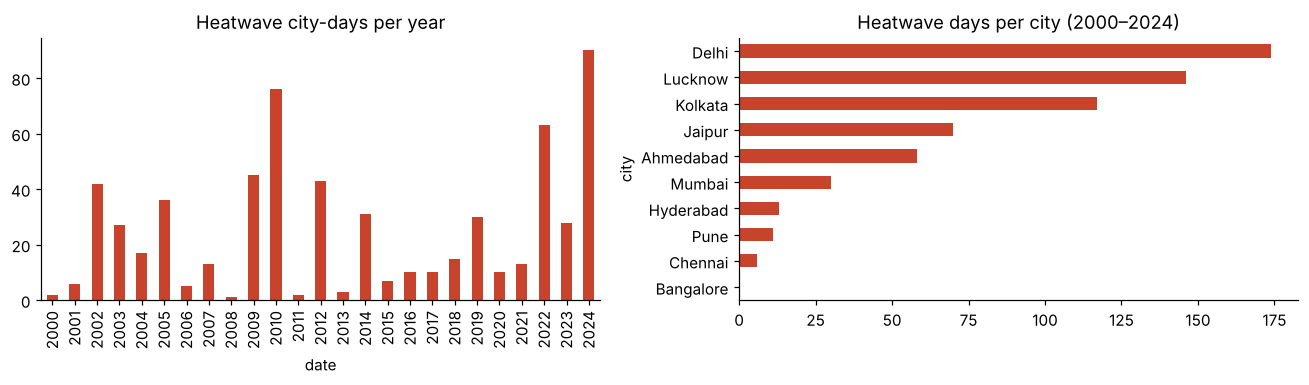

In [4]:
normals = climatology(raw)
df = build_features(raw, normals)
print('heatwave days:', df.hw_today.sum(), '| severe:', df.severe_today.sum())
fig, axs = plt.subplots(1, 2, figsize=(12,3.6))
df.groupby(df.date.dt.year).hw_today.sum().plot.bar(ax=axs[0], color='#C8432B', title='Heatwave city-days per year')
df.groupby('city').hw_today.sum().sort_values().plot.barh(ax=axs[1], color='#C8432B', title='Heatwave days per city (2000–2024)')
plt.tight_layout(); plt.show()

## 3. Features and temporal split

In [5]:
tr, te = split(df)
print(f'development 2000–2020: {len(tr)} rows, {tr.y.sum()} heatwave ({tr.y.mean():.2%})')
print(f'test 2021–2024:        {len(te)} rows, {te.y.sum()} heatwave ({te.y.mean():.2%})')
pd.DataFrame({'feature': FEATURES, 'meaning': [FEATURE_LABELS[f] for f in FEATURES]})

development 2000–2020: 32130 rows, 431 heatwave (1.34%)
test 2021–2024:        6120 rows, 194 heatwave (3.17%)


,feature,meaning
0,margin,"IMD margin, persisted anomaly (°C)"
1,margin3,"IMD margin, 3-day anomaly (°C)"
2,dep,Departure from normal today (°C)
3,dep_mean3,3-day mean departure (°C)
4,tmax_trend3,3-day Tmax trend (°C)
5,app_tmax,Feels-like max today (°C)
6,dtr,Diurnal range Tmax−Tmin (°C)
7,rain7_log,7-day rainfall log(1+mm)
8,wind_max,Max wind speed (km/h)
9,normal_next,Normal Tmax for tomorrow (°C)


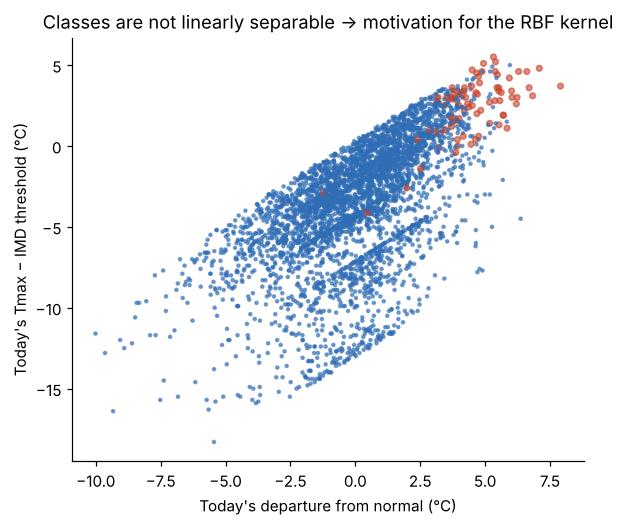

In [6]:
fig, ax = plt.subplots(figsize=(6,5))
s = tr[tr.target_month.between(4,6)].sample(4000, random_state=0)
ax.scatter(s.dep, s.thr_gap, c=np.where(s.y==1,'#C8432B','#2F6DB5'), s=np.where(s.y==1,14,4), alpha=.6)
ax.set(xlabel="Today's departure from normal (°C)", ylabel="Today's Tmax − IMD threshold (°C)",
       title='Classes are not linearly separable → motivation for the RBF kernel'); plt.show()

## 4. SVM with RBF kernel
$K(x,x') = \exp(-\gamma\lVert x-x'\rVert^2)$, decision $f(x)=\sum_i \alpha_i y_i K(x_i,x)+b$.

`src/train.py` tunes **C**, **γ** and the heatwave class weight with year-blocked 5-fold CV (scoring = PR-AUC), chooses the warning threshold from out-of-fold probabilities, then trains on all of 2000–2020. Here we load the saved model and its tuning results.

In [7]:
M = json.load(open('../models/metrics.json'))
print('best:', M['best'])
g = pd.DataFrame(M['grid']['pr_auc'], index=[f'C={c}' for c in M['grid']['C']], columns=[f'γ={x}' for x in M['grid']['gamma']])
g.style.background_gradient(cmap='Reds').format('{:.3f}')

best: {'C': 10, 'gamma': 0.01, 'pos_weight': 5, 'cv_pr_auc': 0.5383, 'threshold': 0.105, 'n_support': [1192, 254], 'weight_scores': {'3': 0.4959, '5': 0.5383, '10': 0.5363}, 'oof_pr_auc': 0.5205, 'oof_roc_auc': 0.9775}


,γ=0.003,γ=0.01,γ=0.03,γ=0.1,γ=0.3
C=0.3,0.506,0.501,0.488,0.478,0.455
C=1,0.509,0.507,0.490,0.471,0.422
C=3,0.515,0.529,0.493,0.462,0.396
C=10,0.532,0.538,0.477,0.442,0.379
C=30,0.533,0.510,0.470,0.423,0.356


## 5. Hold-out evaluation (2021–2024)

In [8]:
model = joblib.load('../models/svm_rbf.joblib')
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
p = model.predict_proba(te[FEATURES].values)[:,1]; thr = M['best']['threshold']
print(classification_report(te.y, (p>=thr).astype(int), target_names=['normal','heatwave'], digits=3))
pd.DataFrame(M['comparison']).set_index('model')[['pr_auc','roc_auc','f1','precision','recall','onset_recall','fp']]

              precision    recall  f1-score   support

      normal      0.990     0.987     0.989      5926
    heatwave      0.637     0.696     0.665       194

    accuracy                          0.978      6120
   macro avg      0.813     0.841     0.827      6120
weighted avg      0.979     0.978     0.978      6120



,pr_auc,roc_auc,f1,precision,recall,onset_recall,fp
model,,,,,,,
SVM — RBF kernel (ours),0.6505,0.9719,0.6650,0.6368,0.6959,0.1449,77
Logistic Regression,0.6647,0.9764,0.6463,0.6382,0.6546,0.1449,72
Linear SVM (no kernel),0.6596,0.9762,0.6537,0.6204,0.6907,0.1449,82
Persistence (today = tomorrow),0.4264,0.8163,0.6443,0.6443,0.6443,0.0000,69


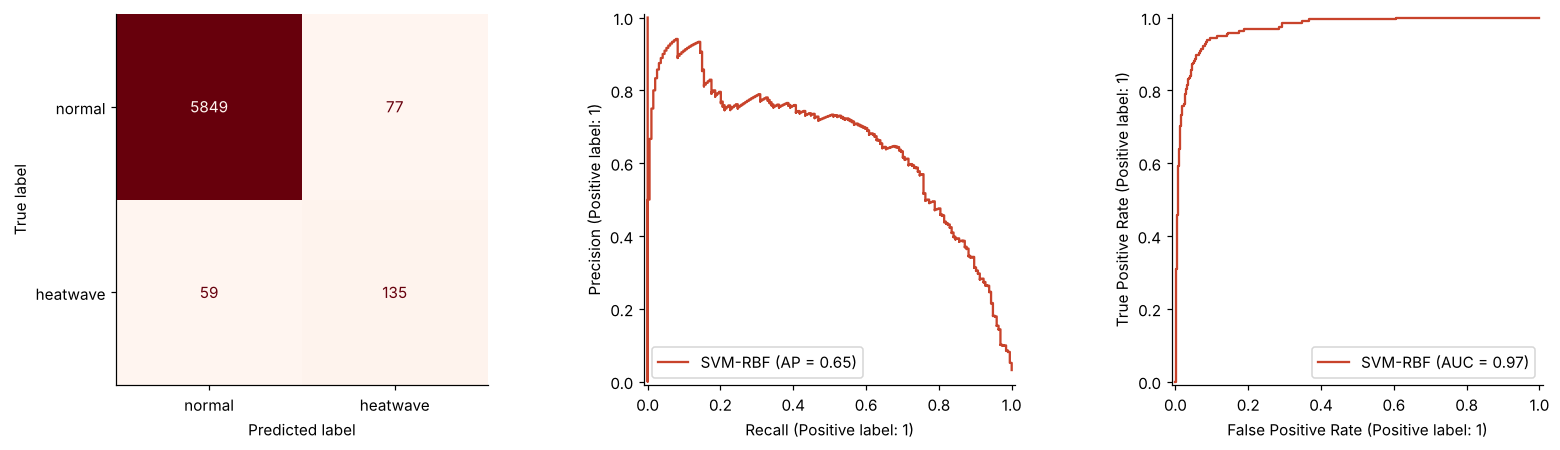

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15,4.2))
ConfusionMatrixDisplay.from_predictions(te.y, (p>=thr).astype(int), display_labels=['normal','heatwave'], ax=axs[0], cmap='Reds', colorbar=False)
PrecisionRecallDisplay.from_predictions(te.y, p, ax=axs[1], name='SVM-RBF', color='#C8432B')
RocCurveDisplay.from_predictions(te.y, p, ax=axs[2], name='SVM-RBF', curve_kwargs={'color':'#C8432B'}); plt.tight_layout(); plt.show()

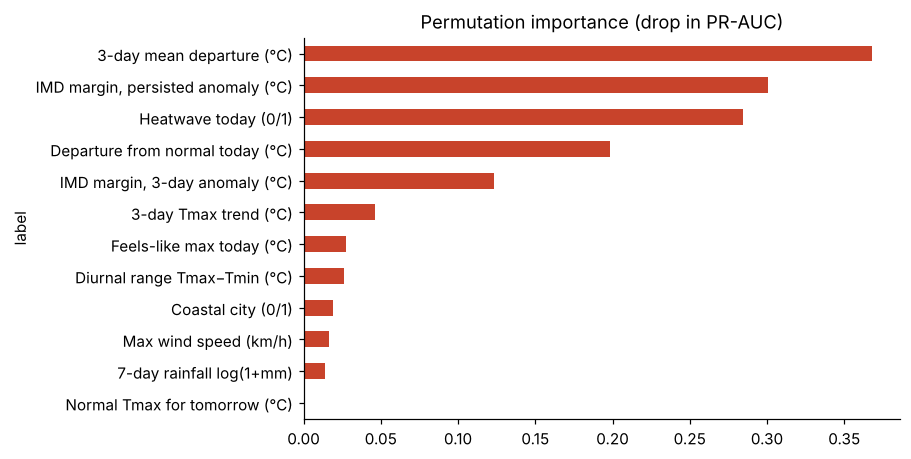

In [10]:
imp = pd.DataFrame(M['importance']).set_index('label')['mean'].sort_values()
imp.plot.barh(figsize=(7,4.5), color='#C8432B', title='Permutation importance (drop in PR-AUC)'); plt.show()

## 6. Season replay — Delhi 2024

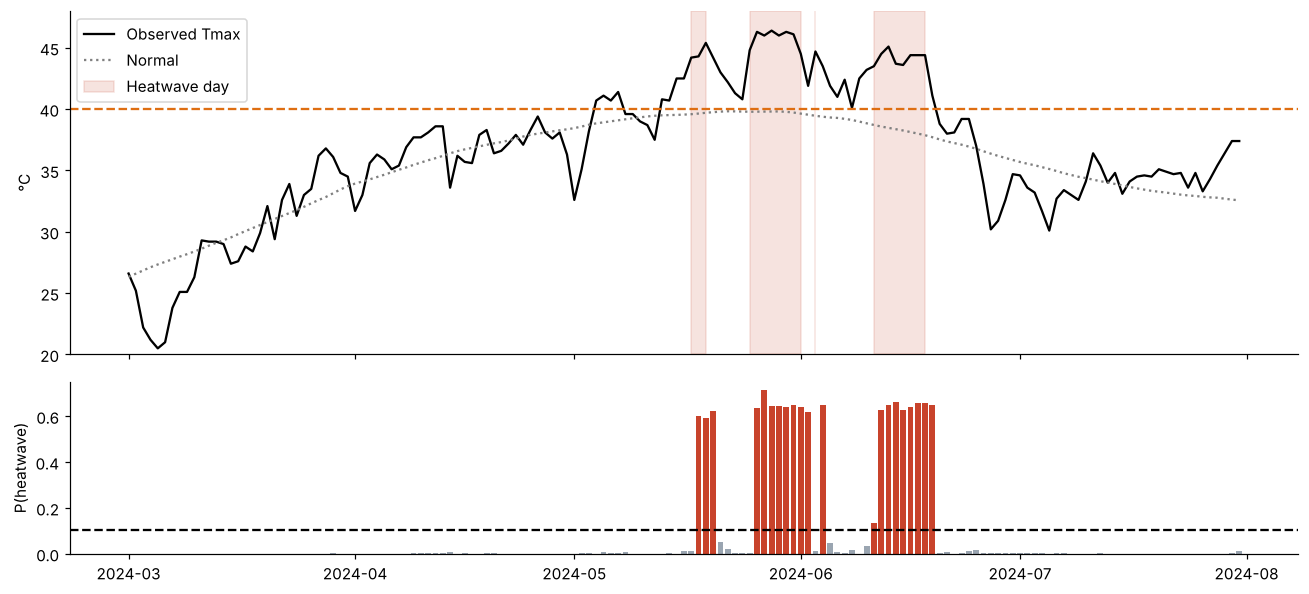

In [11]:
s = te.assign(p=p)[(te.city=='Delhi') & (te.target_year==2024)]
fig, (a, b) = plt.subplots(2, 1, figsize=(12,5.5), sharex=True, gridspec_kw={'height_ratios':[2,1]})
a.plot(s.target_date, s.tmax_next, c='k', label='Observed Tmax'); a.plot(s.target_date, s.tmax_next - s.dep_next, ':', c='grey', label='Normal')
a.axhline(40, ls='--', c='#DE6E12'); a.fill_between(s.target_date, 20, 48, where=s.y==1, color='#C8432B', alpha=.15, label='Heatwave day')
a.set_ylim(20,48); a.legend(loc='upper left'); a.set_ylabel('°C')
b.bar(s.target_date, s.p, color=np.where(s.p>=thr,'#C8432B','#9AA5B1')); b.axhline(thr, ls='--', c='k'); b.set_ylabel('P(heatwave)')
plt.tight_layout(); plt.show()

## 7. Conclusions
* The RBF-kernel SVM gives the best F1 and recall on the unseen 2021–2024 seasons and catches most severe heatwave days.
* Linear models rank days almost as well, because the engineered *IMD margin* features already linearise much of the problem. The kernel's gain is mainly a better operating point.
* The first day of a heatwave spell is the hardest case. Adding NWP forecast inputs is the next step.

See the website (`uvicorn app.main:app`) for the interactive kernel lab and live predictions.